Scaled features loaded for clustering. Shape: (2240, 6)


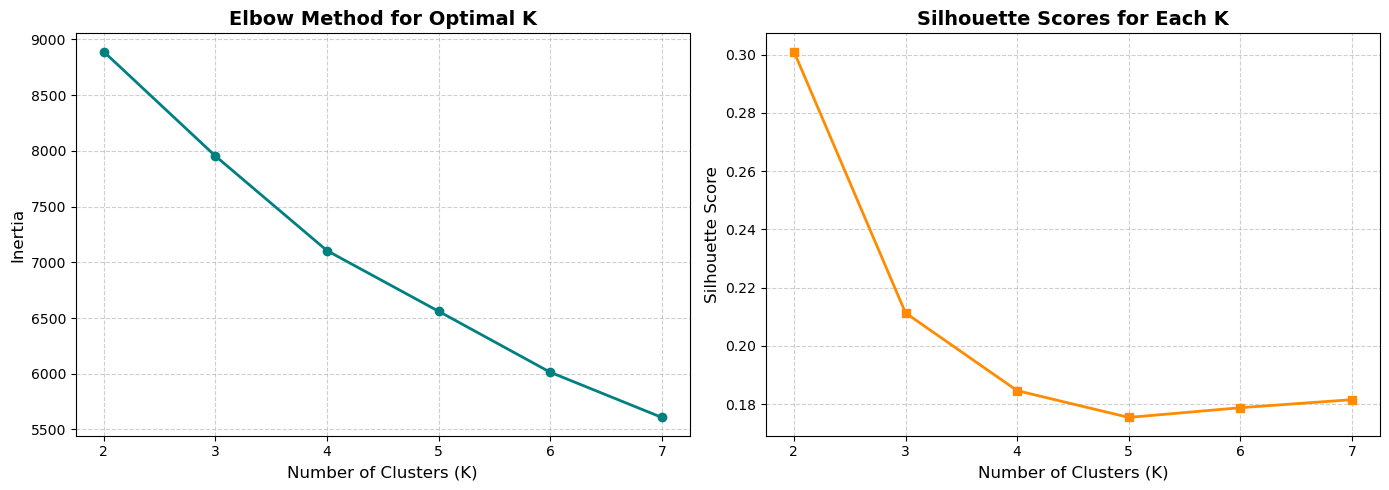

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

# Load the scaled dataset
X_scaled_df = pd.read_csv('scaled_customer_data.csv')

# load the processed customer data
df_processed = pd.read_csv('processed_customer_data.csv')

print(f"Scaled features loaded for clustering. Shape: {X_scaled_df.shape}")

# Use Elbow Method and Silhouette Score to find the optimal number of clusters (K)
inertia = []
silhouette_scores = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled_df)
    inertia.append(kmeans.inertia_)
    score = silhouette_score(X_scaled_df, kmeans.labels_)
    silhouette_scores.append(score)

# Plotting the Elbow Method & Silhouette Scores
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(K_range, inertia, marker='o', color='teal', linewidth=2)
plt.title('Elbow Method for Optimal K', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Inertia', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(K_range, silhouette_scores, marker='s', color='darkorange', linewidth=2)
plt.title('Silhouette Scores for Each K', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [2]:
# Train K-Means Model with Optimal K (K=4) and Assign Cluster Labels
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled_df)

# Add cluster labels back to both processed dataframe and scaled dataframe
df_processed['Cluster'] = cluster_labels
X_scaled_df['Cluster'] = cluster_labels

print(f"K-Means Model successfully trained with K = {optimal_k}")
print("\nCustomer counts in each cluster:")
print(df_processed['Cluster'].value_counts().sort_index())

K-Means Model successfully trained with K = 4

Customer counts in each cluster:
Cluster
0    571
1    616
2    496
3    557
Name: count, dtype: int64


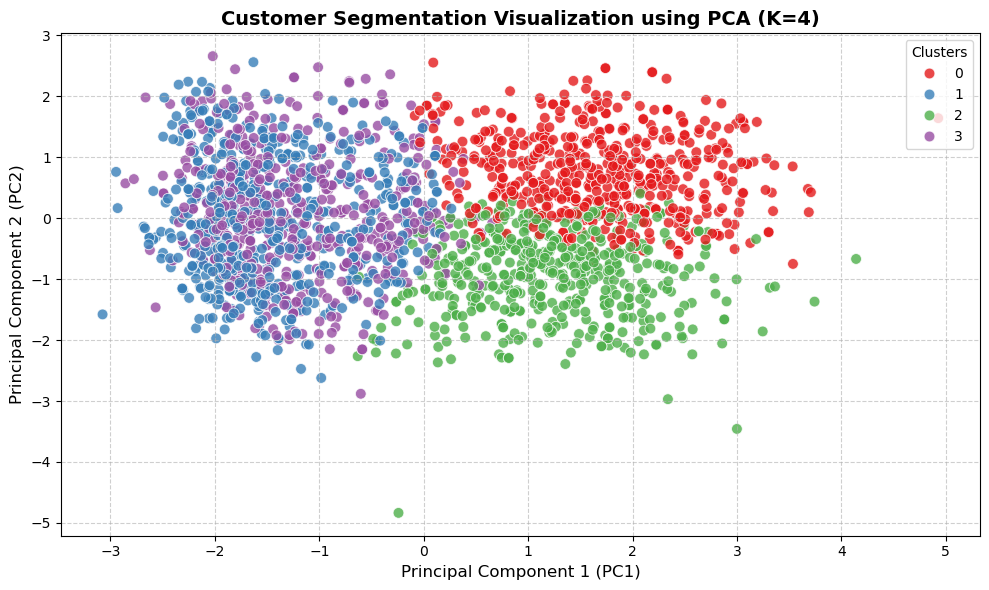


Explained Variance Ratio by PCA components: PC1 = 42.76%, PC2 = 17.66%
Total variance captured by 2D PCA plot: 60.42%


In [3]:
# PCA (Principal Component Analysis) for Cluster Visualization
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Drop the 'Cluster' column temporarily from scaled features for PCA transformation
X_features = X_scaled_df.drop(columns=['Cluster'])

# Apply PCA to reduce dimensions to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_features)

# Create a dataframe for visualization
df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['Cluster'] = X_scaled_df['Cluster'].values

# Plotting the 4 Clusters using PCA
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Cluster', 
    palette='Set1', 
    data=df_pca, 
    alpha=0.8, 
    s=60
)

plt.title('Customer Segmentation Visualization using PCA (K=4)', fontsize=14, fontweight='bold')
plt.xlabel('Principal Component 1 (PC1)', fontsize=12)
plt.ylabel('Principal Component 2 (PC2)', fontsize=12)
plt.legend(title='Clusters', loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Print explained variance ratio to see how much information is retained
explained_variance = pca.explained_variance_ratio_
print(f"\nExplained Variance Ratio by PCA components: PC1 = {explained_variance[0]*100:.2f}%, PC2 = {explained_variance[1]*100:.2f}%")
print(f"Total variance captured by 2D PCA plot: {sum(explained_variance)*100:.2f}%")

In [4]:
# Business Profiling and Cluster Characteristics Summary
# Merge cluster labels back with the full processed dataframe to analyze original numerical features
df_processed['Cluster'] = cluster_labels

# Calculate mean values of key features for each cluster
numeric_cols_for_profiling = ['Age', 'Income', 'Recency', 'Frequency', 'Monetary', 'Customer_Tenure_Days']
cluster_profile = df_processed.groupby('Cluster')[numeric_cols_for_profiling].mean().reset_index()

print("--- Business Profiling: Average Values per Cluster ---")
display(cluster_profile)

# Check the size and percentage of each cluster
cluster_sizes = df_processed['Cluster'].value_counts().sort_index()
cluster_percentage = (cluster_sizes / len(df_processed)) * 100

summary_df = pd.DataFrame({
    'Customer Count': cluster_sizes,
    'Percentage (%)': cluster_percentage.round(2)
})
print("\n--- Cluster Sizes and Distribution ---")
display(summary_df)

--- Business Profiling: Average Values per Cluster ---


,Cluster,Age,Income,Recency,Frequency,Monetary,Customer_Tenure_Days
0,0,58.250438,67559.693520,52.064799,22.618214,1207.876751,538.537653
1,1,53.378247,34266.377435,25.435065,8.592532,122.410714,345.259740
2,2,61.032258,71344.920363,44.570565,19.885081,1027.446069,185.171371
3,3,56.913824,37895.520646,76.303411,9.371634,147.630162,323.149013



--- Cluster Sizes and Distribution ---


,Customer Count,Percentage (%)
Cluster,,
0,571,25.49
1,616,27.50
2,496,22.14
3,557,24.87


In [5]:
# Final export of the clustered dataset
df_processed.to_csv('final_customer_segments.csv', index=False)
print("Final clustered dataset successfully saved as 'final_customer_segments.csv'")

Final clustered dataset successfully saved as 'final_customer_segments.csv'
